In [2]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Independent output folder — does not require Google Drive
RESULTS_DIR = "/kaggle/working/final_comparison"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Recorded results from the completed experiments
results = [
    {
        "Model": "Basic Transformer",
        "Architecture": "Custom encoder-decoder Transformer",
        "Adaptation": "Trained from scratch",
        "BLEU": 13.0148,
        "chrF": 6.1098,
        "Training Time (min)": 2.54,
        "Inference Time (sec/1000)": 73.141,
        "Parameters": 4783232,
        "Decoding": "Greedy",
        "Trainable Parameters": np.nan
    },
    {
        "Model": "mT5-small",
        "Architecture": "Encoder-decoder Transformer",
        "Adaptation": "Full fine-tuning",
        "BLEU": 1.5833,
        "chrF": 11.4274,
        "Training Time (min)": 26.89,
        "Inference Time (sec/1000)": 124.400,
        "Parameters": 300176768,
        "Decoding": "Greedy",
        "Trainable Parameters": np.nan
    },
    {
        "Model": "OPUS-MT",
        "Architecture": "Marian encoder-decoder",
        "Adaptation": "Pretrained baseline; no fine-tuning",
        "BLEU": 42.5432,
        "chrF": 64.8982,
        "Training Time (min)": 0.00,
        "Inference Time (sec/1000)": 43.270,
        "Parameters": 77943296,
        "Decoding": "Beam search (4 beams)",
        "Trainable Parameters": np.nan
    },
    {
        "Model": "TinyLlama 1.1B",
        "Architecture": "Decoder-only Transformer",
        "Adaptation": "4-bit QLoRA",
        "BLEU": 23.8893,
        "chrF": 48.2915,
        "Training Time (min)": 62.96,
        "Inference Time (sec/1000)": 1150.440,
        "Parameters": 1102301184,
        "Decoding": "Greedy",
        "Trainable Parameters": 2252800
    },
    {
        "Model": "Gemma 2B IT",
        "Architecture": "Decoder-only Transformer",
        "Adaptation": "4-bit QLoRA",
        "BLEU": 29.4843,
        "chrF": 53.2853,
        "Training Time (min)": 51.92,
        "Inference Time (sec/1000)": 656.920,
        "Parameters": 2515978240,
        "Decoding": "Greedy",
        "Trainable Parameters": 9805824
    }
]

comparison_df = pd.DataFrame(results)

# Save the detailed comparison
csv_path = os.path.join(
    RESULTS_DIR, "final_model_comparison_detailed.csv"
)
comparison_df.to_csv(csv_path, index=False)

print("Comparison table created successfully.")
print("Saved to:", csv_path)
display(comparison_df)

Comparison table created successfully.
Saved to: /kaggle/working/final_comparison/final_model_comparison_detailed.csv


,Model,Architecture,Adaptation,BLEU,chrF,Training Time (min),Inference Time (sec/1000),Parameters,Decoding,Trainable Parameters
0,Basic Transformer,Custom encoder-decoder Transformer,Trained from scratch,13.0148,6.1098,2.54,73.141,4783232,Greedy,NaN
1,mT5-small,Encoder-decoder Transformer,Full fine-tuning,1.5833,11.4274,26.89,124.400,300176768,Greedy,NaN
2,OPUS-MT,Marian encoder-decoder,Pretrained baseline; no fine-tuning,42.5432,64.8982,0.00,43.270,77943296,Beam search (4 beams),NaN
3,TinyLlama 1.1B,Decoder-only Transformer,4-bit QLoRA,23.8893,48.2915,62.96,1150.440,1102301184,Greedy,2252800.0
4,Gemma 2B IT,Decoder-only Transformer,4-bit QLoRA,29.4843,53.2853,51.92,656.920,2515978240,Greedy,9805824.0


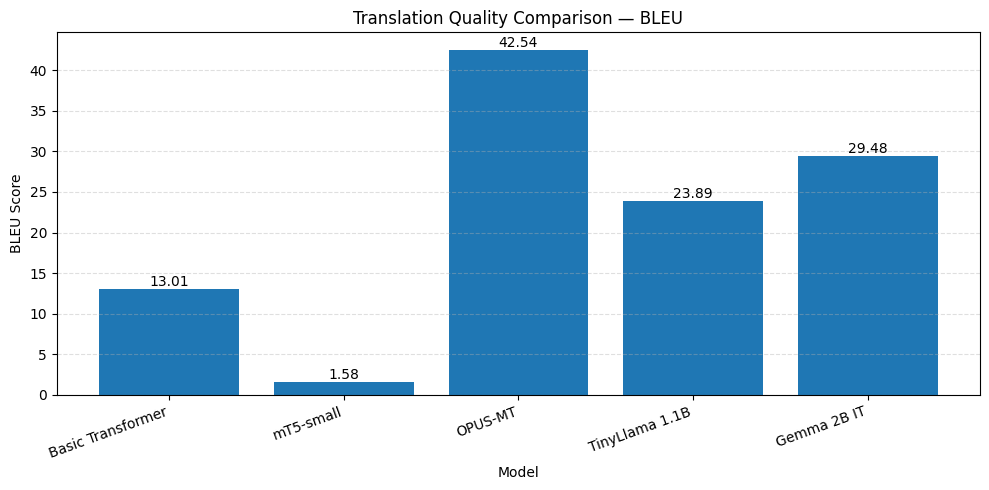

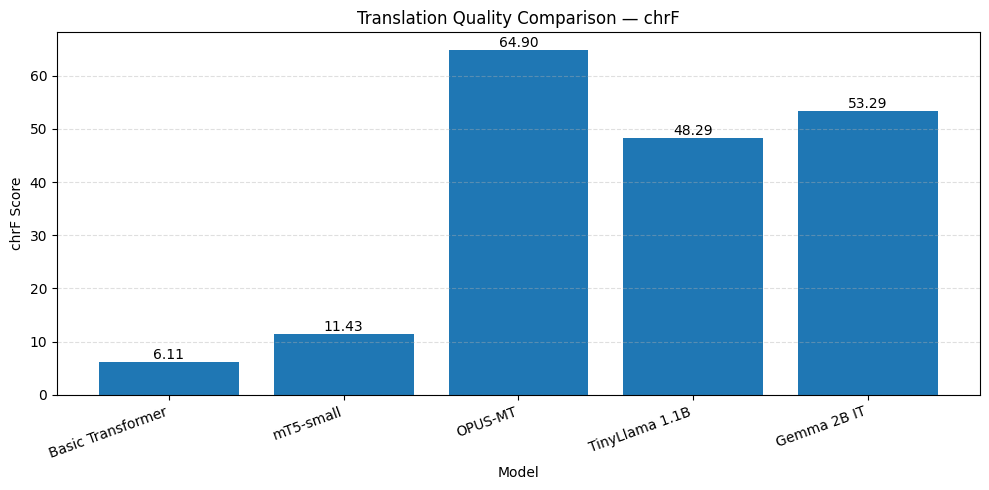

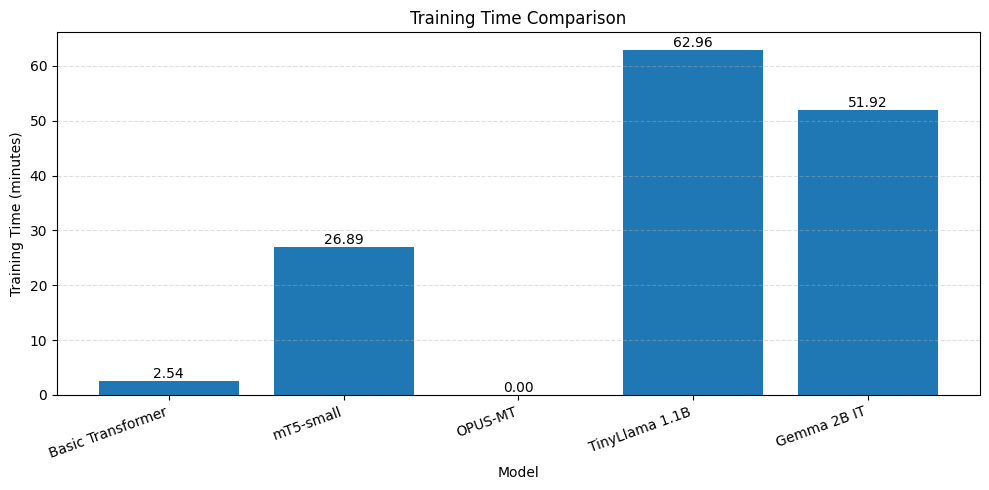

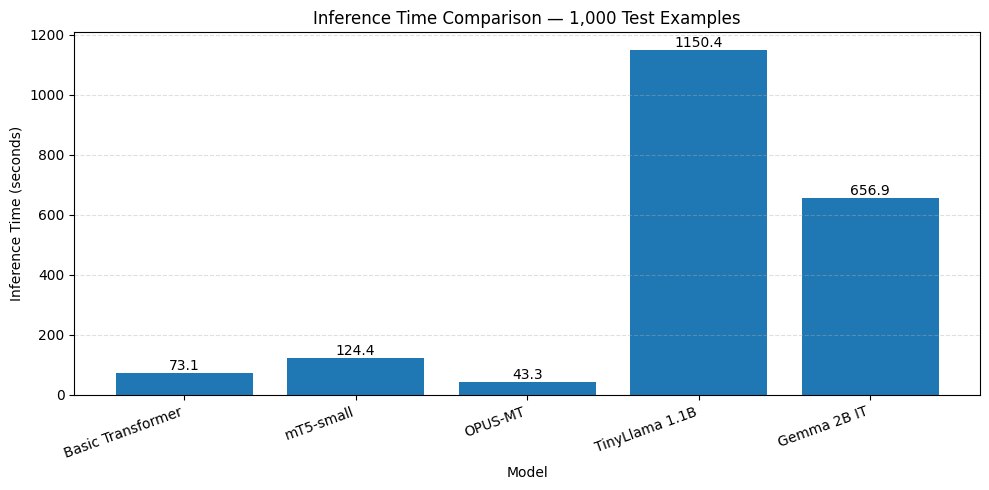

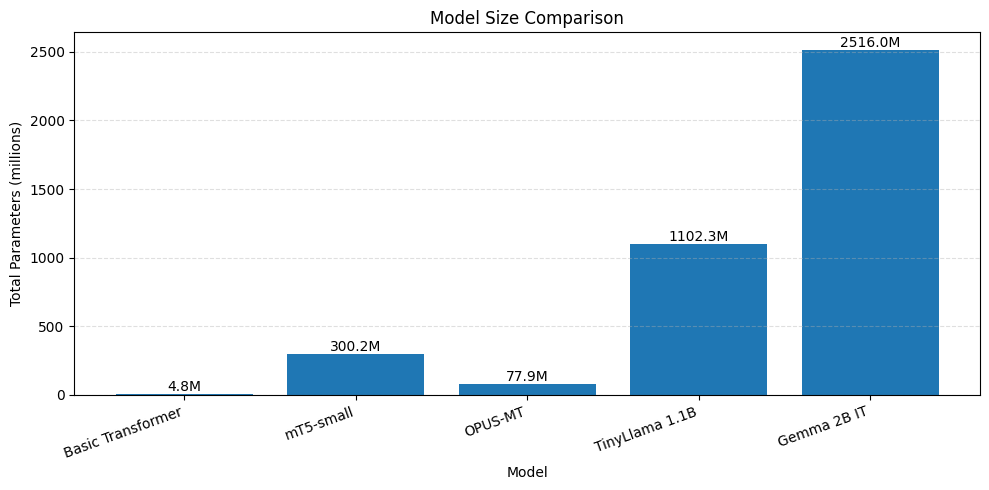

All five charts saved to: /kaggle/working/final_comparison
Files:
 - comparison_bleu.png
 - comparison_chrf.png
 - comparison_inference_time.png
 - comparison_parameters.png
 - comparison_training_time.png


In [4]:
# Cell 2: Visual comparison of model performance

import matplotlib.pyplot as plt
import os

# Consistent model ordering
models = comparison_df["Model"].tolist()

# 1. Translation quality: BLEU
plt.figure(figsize=(10, 5))
bars = plt.bar(models, comparison_df["BLEU"])
plt.title("Translation Quality Comparison — BLEU")
plt.ylabel("BLEU Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, comparison_df["BLEU"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "comparison_bleu.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. Translation quality: chrF
plt.figure(figsize=(10, 5))
bars = plt.bar(models, comparison_df["chrF"])
plt.title("Translation Quality Comparison — chrF")
plt.ylabel("chrF Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, comparison_df["chrF"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "comparison_chrf.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Training time
plt.figure(figsize=(10, 5))
bars = plt.bar(models, comparison_df["Training Time (min)"])
plt.title("Training Time Comparison")
plt.ylabel("Training Time (minutes)")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, comparison_df["Training Time (min)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "comparison_training_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 4. Inference time per 1,000 examples
plt.figure(figsize=(10, 5))
bars = plt.bar(models, comparison_df["Inference Time (sec/1000)"])
plt.title("Inference Time Comparison — 1,000 Test Examples")
plt.ylabel("Inference Time (seconds)")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, comparison_df["Inference Time (sec/1000)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "comparison_inference_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 5. Total parameter count
plt.figure(figsize=(10, 5))
bars = plt.bar(
    models,
    comparison_df["Parameters"] / 1_000_000
)
plt.title("Model Size Comparison")
plt.ylabel("Total Parameters (millions)")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, comparison_df["Parameters"] / 1_000_000):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}M",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "comparison_parameters.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("All five charts saved to:", RESULTS_DIR)
print("Files:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    if filename.endswith(".png"):
        print(" -", filename)

In [5]:
# Cell 3: Quantitative analysis and report-ready conclusions

from pathlib import Path

df = comparison_df.copy()

# Identify top-performing models for each metric
best_bleu = df.loc[df["BLEU"].idxmax()]
best_chrf = df.loc[df["chrF"].idxmax()]
fastest_inference = df.loc[df["Inference Time (sec/1000)"].idxmin()]

# Exclude the pretrained baseline from the additional-training comparison
trained_models = df[df["Model"] != "OPUS-MT"]
fastest_training = trained_models.loc[
    trained_models["Training Time (min)"].idxmin()
]

# Model size conversions
df["Parameters (M)"] = df["Parameters"] / 1_000_000

lines = [
    "# Final Model Comparison: Results and Discussion",
    "",
    "## 1. Overview",
    "",
    "Five translation systems were evaluated for English-to-Spanish translation: "
    "a custom Transformer trained from scratch, mT5-small with full fine-tuning, "
    "OPUS-MT as a pretrained baseline, and TinyLlama and Gemma adapted using 4-bit QLoRA.",
    "",
    "BLEU measures n-gram overlap with reference translations, while chrF measures "
    "character n-gram similarity. Neither metric alone fully captures meaning, fluency, "
    "or grammatical correctness.",
    "",
    "## 2. Translation quality",
    "",
    f"- **Highest BLEU:** {best_bleu['Model']} ({best_bleu['BLEU']:.4f}).",
    f"- **Highest chrF:** {best_chrf['Model']} ({best_chrf['chrF']:.4f}).",
    f"- OPUS-MT achieved BLEU {df.loc[df['Model'] == 'OPUS-MT', 'BLEU'].iloc[0]:.4f} "
    f"and chrF {df.loc[df['Model'] == 'OPUS-MT', 'chrF'].iloc[0]:.4f}, "
    "the highest scores among the evaluated systems.",
    "- Gemma 2B IT outperformed TinyLlama 1.1B on both recorded metrics.",
    "- The custom Transformer achieved a higher BLEU score than mT5-small, "
    "while mT5-small achieved a higher chrF score than the custom Transformer.",
    "",
    "These results indicate that the pretrained OPUS-MT baseline was the strongest "
    "translation system in this experiment. The results do not establish that "
    "pretraining or model size alone caused the differences, because architecture, "
    "tokenization, adaptation, decoding, and implementation also differed.",
    "",
    "## 3. Computational performance",
    "",
    f"- **Fastest measured inference:** {fastest_inference['Model']} "
    f"({fastest_inference['Inference Time (sec/1000)']:.3f} seconds per 1,000 examples).",
    f"- **Shortest additional training among trained models:** {fastest_training['Model']} "
    f"({fastest_training['Training Time (min)']:.2f} minutes).",
    "- OPUS-MT required no additional training in this experiment, so its training "
    "time is recorded as 0.00 minutes; this does not mean that pretraining was free.",
    "- TinyLlama and Gemma had substantially longer measured inference times than "
    "the encoder-decoder systems in this setup.",
    "",
    "Inference timings are specific to the recorded hardware, batch sizes, generation "
    "settings, and implementation. They should not be treated as hardware-independent "
    "benchmarks.",
    "",
    "## 4. Model size and parameter-efficient adaptation",
    "",
    "- The custom Transformer had 4.78 million total parameters.",
    "- mT5-small had approximately 300.18 million total parameters.",
    "- OPUS-MT had approximately 77.94 million total parameters.",
    "- TinyLlama had approximately 1,102.30 million total parameters, with "
    "2.25 million trainable LoRA parameters reported.",
    "- Gemma 2B IT had approximately 2,515.98 million total parameters by the "
    "recorded PEFT parameter count, with 9.81 million trainable LoRA parameters.",
    "",
    "For the QLoRA models, only the adapter parameters were trained; the base model "
    "was loaded in 4-bit quantized form. The total parameter counts and trainable "
    "parameter counts therefore describe different quantities. Parameter counts for "
    "quantized models can also vary by counting method.",
    "",
    "## 5. Interpretation of individual models",
    "",
    "### Basic Transformer",
    "The custom model was computationally inexpensive to train, but its low chrF "
    "score indicates weak character-level agreement with the references. A model "
    "trained from scratch on a relatively limited parallel corpus may struggle to "
    "learn robust translation representations.",
    "",
    "### mT5-small",
    "Despite full fine-tuning, mT5-small recorded low BLEU and modest chrF in this "
    "experiment. Its outputs and metrics should be interpreted as the result of this "
    "specific training configuration, preprocessing, and evaluation—not as a general "
    "claim that mT5 is unsuitable for translation.",
    "",
    "### OPUS-MT",
    "OPUS-MT delivered the strongest recorded translation metrics and the fastest "
    "measured inference. Its pretrained English-to-Spanish translation capability "
    "provides a useful reference point for evaluating the models adapted in this project.",
    "",
    "### TinyLlama 1.1B",
    "QLoRA made adaptation possible without updating all base-model parameters. "
    "However, the measured inference time was high relative to the encoder-decoder "
    "models, and translation quality remained below OPUS-MT.",
    "",
    "### Gemma 2B IT",
    "Gemma achieved higher BLEU and chrF than TinyLlama in the recorded evaluation, "
    "with shorter inference time than TinyLlama. It still did not exceed OPUS-MT "
    "on either translation metric.",
    "",
    "## 6. Important experimental limitations",
    "",
    "- The models use different architectures, pretrained checkpoints, tokenizers, "
    "adaptation methods, and decoding strategies.",
    "- OPUS-MT uses beam search with four beams, while the other recorded evaluations "
    "use greedy decoding.",
    "- Training times do not include the original pretraining cost of pretrained models.",
    "- BLEU and chrF are automatic metrics; manual review is needed to assess adequacy, "
    "fluency, omissions, and meaning preservation.",
    "- The conclusions apply to the recorded test evaluation and configuration. "
    "Repeated runs and broader test data would help assess variability and generalization.",
    "",
    "## 7. Conclusion",
    "",
    "Under the configurations tested, OPUS-MT was the strongest overall choice for "
    "English-to-Spanish translation, achieving the highest BLEU and chrF scores and "
    "the lowest measured inference time. Gemma outperformed TinyLlama on both recorded "
    "translation metrics, while the custom Transformer was the least expensive to "
    "train but produced weak translation-quality scores. The experiment illustrates "
    "that pretrained task-specific translation systems can be highly competitive "
    "against general-purpose models adapted with parameter-efficient fine-tuning.",
    "",
    "The results should be interpreted as a comparison of complete experimental systems, "
    "rather than a controlled test of architecture alone."
]

analysis_text = "\n".join(lines)

analysis_path = os.path.join(
    RESULTS_DIR, "final_results_analysis.md"
)

with open(analysis_path, "w", encoding="utf-8") as f:
    f.write(analysis_text)

print("Analysis saved to:", analysis_path)
print("\nKey findings:")
print(f"Best BLEU: {best_bleu['Model']} — {best_bleu['BLEU']:.4f}")
print(f"Best chrF: {best_chrf['Model']} — {best_chrf['chrF']:.4f}")
print(
    f"Fastest inference: {fastest_inference['Model']} — "
    f"{fastest_inference['Inference Time (sec/1000)']:.3f} sec/1000"
)
print("\nAnalysis preview:\n")
print(analysis_text[:2500])

Analysis saved to: /kaggle/working/final_comparison/final_results_analysis.md

Key findings:
Best BLEU: OPUS-MT — 42.5432
Best chrF: OPUS-MT — 64.8982
Fastest inference: OPUS-MT — 43.270 sec/1000

Analysis preview:

# Final Model Comparison: Results and Discussion

## 1. Overview

Five translation systems were evaluated for English-to-Spanish translation: a custom Transformer trained from scratch, mT5-small with full fine-tuning, OPUS-MT as a pretrained baseline, and TinyLlama and Gemma adapted using 4-bit QLoRA.

BLEU measures n-gram overlap with reference translations, while chrF measures character n-gram similarity. Neither metric alone fully captures meaning, fluency, or grammatical correctness.

## 2. Translation quality

- **Highest BLEU:** OPUS-MT (42.5432).
- **Highest chrF:** OPUS-MT (64.8982).
- OPUS-MT achieved BLEU 42.5432 and chrF 64.8982, the highest scores among the evaluated systems.
- Gemma 2B IT outperformed TinyLlama 1.1B on both recorded metrics.
- The custom Transf

In [6]:
# Cell 4: Create a downloadable results bundle

import os
import zipfile

RESULTS_DIR = "/kaggle/working/final_comparison"
ZIP_PATH = "/kaggle/working/final_comparison_results.zip"

required_files = [
    "final_model_comparison_detailed.csv",
    "comparison_bleu.png",
    "comparison_chrf.png",
    "comparison_training_time.png",
    "comparison_inference_time.png",
    "comparison_parameters.png",
    "final_results_analysis.md"
]

missing_files = [
    filename for filename in required_files
    if not os.path.isfile(os.path.join(RESULTS_DIR, filename))
]

if missing_files:
    print("Cannot create complete bundle. Missing files:")
    for filename in missing_files:
        print(" -", filename)
else:
    with zipfile.ZipFile(
        ZIP_PATH, mode="w", compression=zipfile.ZIP_DEFLATED
    ) as zipf:
        for filename in required_files:
            file_path = os.path.join(RESULTS_DIR, filename)
            zipf.write(file_path, arcname=filename)

    print("ZIP bundle created successfully:", ZIP_PATH)
    print(f"Files included: {len(required_files)}")
    print(f"ZIP size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB")

    with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
        print("\nVerified contents:")
        for filename in zipf.namelist():
            print(" -", filename)

ZIP bundle created successfully: /kaggle/working/final_comparison_results.zip
Files included: 7
ZIP size: 0.60 MB

Verified contents:
 - final_model_comparison_detailed.csv
 - comparison_bleu.png
 - comparison_chrf.png
 - comparison_training_time.png
 - comparison_inference_time.png
 - comparison_parameters.png
 - final_results_analysis.md


In [7]:
# Step 2, Cell 1: Gemma temperature and sampling analysis

import os
import pandas as pd
import numpy as np

RESULTS_DIR = "/kaggle/working/final_comparison"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Previously recorded results on the 100-example subset
sampling_results = [
    {
        "Model": "Gemma 2B IT",
        "Decoding": "Greedy",
        "Temperature": 0.0,
        "Top-p": np.nan,
        "Test Examples": 100,
        "BLEU": 29.4521,
        "chrF": 53.3279,
        "Inference Time (sec)": 66.44,
        "Inference Time (sec/example)": 66.44 / 100
    },
    {
        "Model": "Gemma 2B IT",
        "Decoding": "Sampling",
        "Temperature": 0.7,
        "Top-p": 0.9,
        "Test Examples": 100,
        "BLEU": 24.7170,
        "chrF": 48.5303,
        "Inference Time (sec)": 65.66,
        "Inference Time (sec/example)": 65.66 / 100
    },
    {
        "Model": "Gemma 2B IT",
        "Decoding": "Sampling",
        "Temperature": 1.0,
        "Top-p": 0.9,
        "Test Examples": 100,
        "BLEU": 21.6606,
        "chrF": 45.8957,
        "Inference Time (sec)": 64.09,
        "Inference Time (sec/example)": 64.09 / 100
    }
]

sampling_df = pd.DataFrame(sampling_results)

# Differences relative to greedy decoding
greedy = sampling_df.loc[sampling_df["Decoding"] == "Greedy"].iloc[0]

sampling_df["BLEU Difference vs Greedy"] = (
    sampling_df["BLEU"] - greedy["BLEU"]
)
sampling_df["chrF Difference vs Greedy"] = (
    sampling_df["chrF"] - greedy["chrF"]
)

csv_path = os.path.join(
    RESULTS_DIR, "gemma_sampling_analysis.csv"
)
sampling_df.to_csv(csv_path, index=False)

display(sampling_df.round(4))

print("\nSaved sampling comparison to:", csv_path)

,Model,Decoding,Temperature,Top-p,Test Examples,BLEU,chrF,Inference Time (sec),Inference Time (sec/example),BLEU Difference vs Greedy,chrF Difference vs Greedy
0,Gemma 2B IT,Greedy,0.0,NaN,100,29.4521,53.3279,66.44,0.6644,0.0000,0.0000
1,Gemma 2B IT,Sampling,0.7,0.9,100,24.7170,48.5303,65.66,0.6566,-4.7351,-4.7976
2,Gemma 2B IT,Sampling,1.0,0.9,100,21.6606,45.8957,64.09,0.6409,-7.7915,-7.4322



Saved sampling comparison to: /kaggle/working/final_comparison/gemma_sampling_analysis.csv


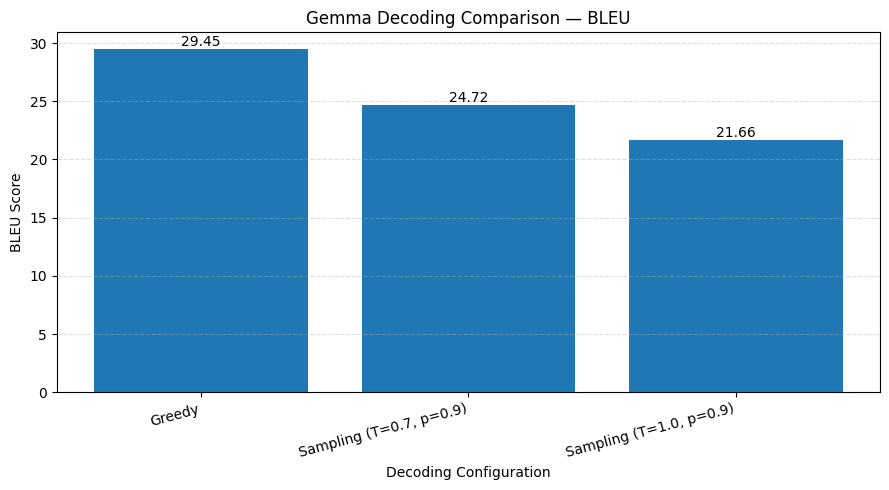

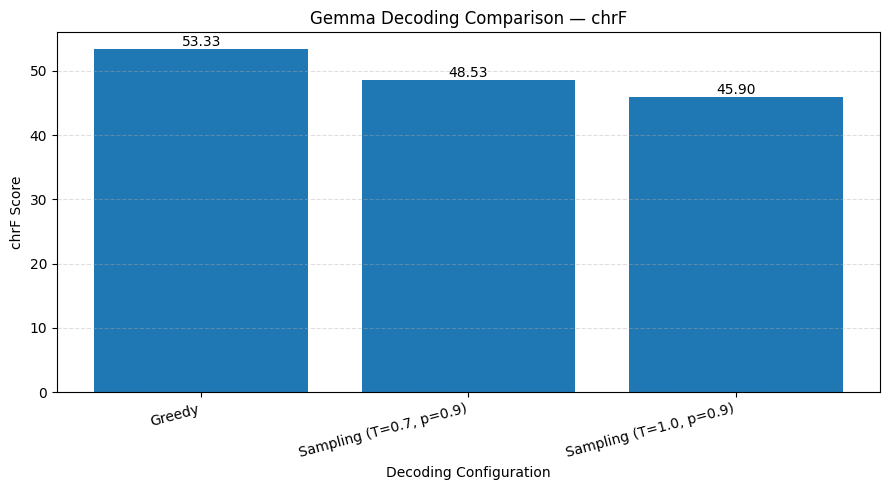

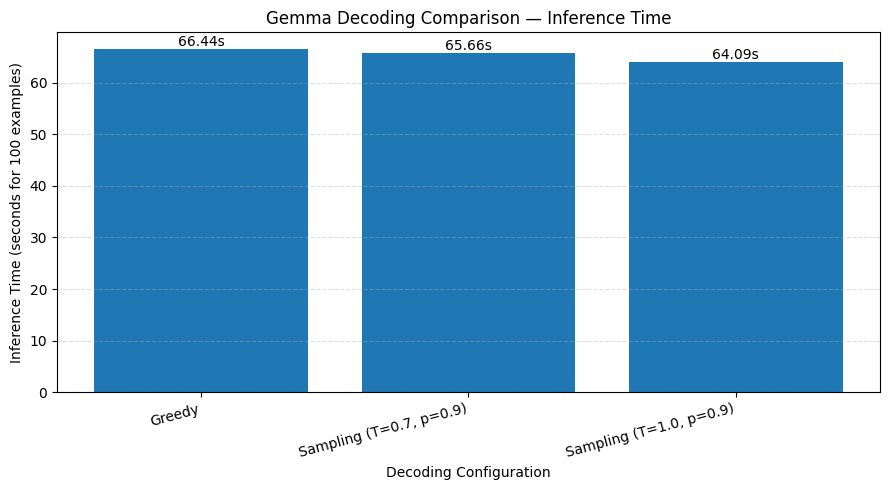

Saved sampling charts:
/kaggle/working/final_comparison/gemma_sampling_bleu.png
/kaggle/working/final_comparison/gemma_sampling_chrf.png
/kaggle/working/final_comparison/gemma_sampling_inference_time.png


In [8]:
# Step 2, Cell 2: Visualize Gemma decoding results

import os
import matplotlib.pyplot as plt

RESULTS_DIR = "/kaggle/working/final_comparison"

# Use labels that clearly show the decoding configuration
sampling_df["Configuration"] = [
    "Greedy",
    "Sampling (T=0.7, p=0.9)",
    "Sampling (T=1.0, p=0.9)"
]

# 1. BLEU comparison
plt.figure(figsize=(9, 5))
bars = plt.bar(sampling_df["Configuration"], sampling_df["BLEU"])
plt.title("Gemma Decoding Comparison — BLEU")
plt.ylabel("BLEU Score")
plt.xlabel("Decoding Configuration")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, sampling_df["BLEU"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "gemma_sampling_bleu.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 2. chrF comparison
plt.figure(figsize=(9, 5))
bars = plt.bar(sampling_df["Configuration"], sampling_df["chrF"])
plt.title("Gemma Decoding Comparison — chrF")
plt.ylabel("chrF Score")
plt.xlabel("Decoding Configuration")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, sampling_df["chrF"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "gemma_sampling_chrf.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 3. Inference time comparison
plt.figure(figsize=(9, 5))
bars = plt.bar(
    sampling_df["Configuration"],
    sampling_df["Inference Time (sec)"]
)
plt.title("Gemma Decoding Comparison — Inference Time")
plt.ylabel("Inference Time (seconds for 100 examples)")
plt.xlabel("Decoding Configuration")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, sampling_df["Inference Time (sec)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "gemma_sampling_inference_time.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("Saved sampling charts:")
for filename in [
    "gemma_sampling_bleu.png",
    "gemma_sampling_chrf.png",
    "gemma_sampling_inference_time.png"
]:
    print(os.path.join(RESULTS_DIR, filename))

In [9]:
# Step 2, Cell 3: Write report-ready sampling analysis

import os

RESULTS_DIR = "/kaggle/working/final_comparison"

sampling_analysis = r"""
# Gemma Decoding Strategy: Temperature and Sampling Analysis

## 1. Objective

This experiment examined how decoding strategy affects English-to-Spanish
translation quality and inference time for the Gemma 2B IT model. Three
configurations were evaluated on the same 100-example test subset:

- Greedy decoding
- Sampling with temperature 0.7 and top-p 0.9
- Sampling with temperature 1.0 and top-p 0.9

The results are reported separately from the main 1,000-example evaluation.

## 2. Results

| Decoding configuration | BLEU | chrF | Inference time (100 examples) |
|---|---:|---:|---:|
| Greedy | 29.4521 | 53.3279 | 66.44 s |
| Sampling (T=0.7, top-p=0.9) | 24.7170 | 48.5303 | 65.66 s |
| Sampling (T=1.0, top-p=0.9) | 21.6606 | 45.8957 | 64.09 s |

## 3. Translation quality

Greedy decoding achieved the highest scores for both evaluation metrics,
with BLEU 29.4521 and chrF 53.3279.

Compared with greedy decoding:

- Sampling at temperature 0.7 reduced BLEU by 4.7351 points and chrF
  by 4.7976 points.
- Sampling at temperature 1.0 reduced BLEU by 7.7915 points and chrF
  by 7.4322 points.

In this experiment, the higher-temperature configuration produced the
lowest BLEU and chrF scores. This is consistent with sampled outputs
matching the reference translations less closely according to these
automatic metrics.

## 4. Inference time

The measured inference times were 66.44 seconds for greedy decoding,
65.66 seconds for temperature 0.7 sampling, and 64.09 seconds for
temperature 1.0 sampling over the 100 examples.

The observed differences were small. These measurements alone do not
establish that sampling is inherently faster than greedy decoding;
timings may vary with execution conditions and generation settings.

## 5. Interpretation

For this test subset and these settings, greedy decoding provided the
best reference-based translation scores. Increasing the sampling
temperature from 0.7 to 1.0 was associated with lower BLEU and chrF.

Sampling introduces variation into token selection, whereas greedy
decoding selects the highest-probability next token at each generation
step. More varied outputs are not necessarily more accurate translations.

BLEU and chrF measure similarity to reference translations. They do
not directly measure creativity, semantic adequacy, or every aspect
of fluency. Therefore, these results should not be interpreted as
proof that greedy decoding is always superior for translation.

## 6. Limitations

- The experiment used only 100 test examples, not the full 1,000-example
  evaluation set.
- The results apply to the tested model, prompts, and decoding settings.
- A single recorded run does not quantify variation across random seeds.
- Automatic metrics should be supplemented with human review of meaning,
  grammaticality, omissions, and fluency when possible.
- The sampling results must not be directly compared with the main
  1,000-example scores as though they came from the same evaluation set.

## 7. Conclusion

On the 100-example subset, greedy decoding achieved the strongest
reference-based translation scores. Sampling with temperature 0.7
and 1.0 produced lower BLEU and chrF, with the largest decrease at
temperature 1.0. The measured inference times were relatively close.

These findings support using greedy decoding as the preferred
configuration among the three tested for this particular evaluation.
Broader testing would be required before generalizing this conclusion.
"""

analysis_path = os.path.join(
    RESULTS_DIR, "gemma_sampling_analysis.md"
)

with open(analysis_path, "w", encoding="utf-8") as f:
    f.write(sampling_analysis.strip() + "\n")

print("Sampling analysis saved to:", analysis_path)
print("\nPreview:\n")
print(sampling_analysis[:2200])

Sampling analysis saved to: /kaggle/working/final_comparison/gemma_sampling_analysis.md

Preview:


# Gemma Decoding Strategy: Temperature and Sampling Analysis

## 1. Objective

This experiment examined how decoding strategy affects English-to-Spanish
translation quality and inference time for the Gemma 2B IT model. Three
configurations were evaluated on the same 100-example test subset:

- Greedy decoding
- Sampling with temperature 0.7 and top-p 0.9
- Sampling with temperature 1.0 and top-p 0.9

The results are reported separately from the main 1,000-example evaluation.

## 2. Results

| Decoding configuration | BLEU | chrF | Inference time (100 examples) |
|---|---:|---:|---:|
| Greedy | 29.4521 | 53.3279 | 66.44 s |
| Sampling (T=0.7, top-p=0.9) | 24.7170 | 48.5303 | 65.66 s |
| Sampling (T=1.0, top-p=0.9) | 21.6606 | 45.8957 | 64.09 s |

## 3. Translation quality

Greedy decoding achieved the highest scores for both evaluation metrics,
with BLEU 29.4521 and chrF 53.3279.

Compare

In [10]:
# Step 2, Cell 4: Package sampling results

import os
import zipfile

RESULTS_DIR = "/kaggle/working/final_comparison"
ZIP_PATH = "/kaggle/working/gemma_sampling_analysis_bundle.zip"

required_files = [
    "gemma_sampling_analysis.csv",
    "gemma_sampling_bleu.png",
    "gemma_sampling_chrf.png",
    "gemma_sampling_inference_time.png",
    "gemma_sampling_analysis.md"
]

missing = [
    name for name in required_files
    if not os.path.isfile(os.path.join(RESULTS_DIR, name))
]

if missing:
    print("Missing required files:")
    for name in missing:
        print(" -", name)
else:
    with zipfile.ZipFile(
        ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
    ) as zipf:
        for name in required_files:
            zipf.write(
                os.path.join(RESULTS_DIR, name),
                arcname=name
            )

    with zipfile.ZipFile(ZIP_PATH, "r") as zipf:
        print("Bundle created and verified:", ZIP_PATH)
        print("Files included:")
        for name in zipf.namelist():
            print(" -", name)

    print(
        f"\nZIP size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB"
    )

Bundle created and verified: /kaggle/working/gemma_sampling_analysis_bundle.zip
Files included:
 - gemma_sampling_analysis.csv
 - gemma_sampling_bleu.png
 - gemma_sampling_chrf.png
 - gemma_sampling_inference_time.png
 - gemma_sampling_analysis.md

ZIP size: 0.30 MB
